# 1. Histogram Stretching 

## 1) 제시된 LUT(look up table)을 생성하시오. (모든 LUT은 uint8의 형태로 저장하시오) 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skimage.exposure as ex

In [2]:
# Input intensity: 0 ~ 255
x = np.arange(256)

# LUT1: y = 2x
LUT1 = np.uint8(np.clip(2 * x, 0, 255))

# LUT2: y = (1/2)x
LUT2 = np.uint8(0.5 * x)

# LUT3: y = -x + 255
LUT3 = np.uint8(-x + 255)

# LUT4: piecewise linear transformation
t1 = (32 / 96) * np.arange(0, 97)

t2 = ((192 - 32) / (200 - 96)) * \
     (np.arange(97, 201) - 96) + 32

t3 = ((255 - 192) / (255 - 200)) * \
     (np.arange(201, 256) - 200) + 192

LUT4 = np.uint8(
    np.floor(np.concatenate((t1, t2, t3)))
)

In [3]:
print(LUT1.dtype, LUT2.dtype, LUT3.dtype, LUT4.dtype)
print(len(LUT1), len(LUT2), len(LUT3), len(LUT4))

uint8 uint8 uint8 uint8
256 256 256 256


## 2) 1)에서 생성한 LUT 4개를 하나의 figure에 출력하시오.(subplot) 

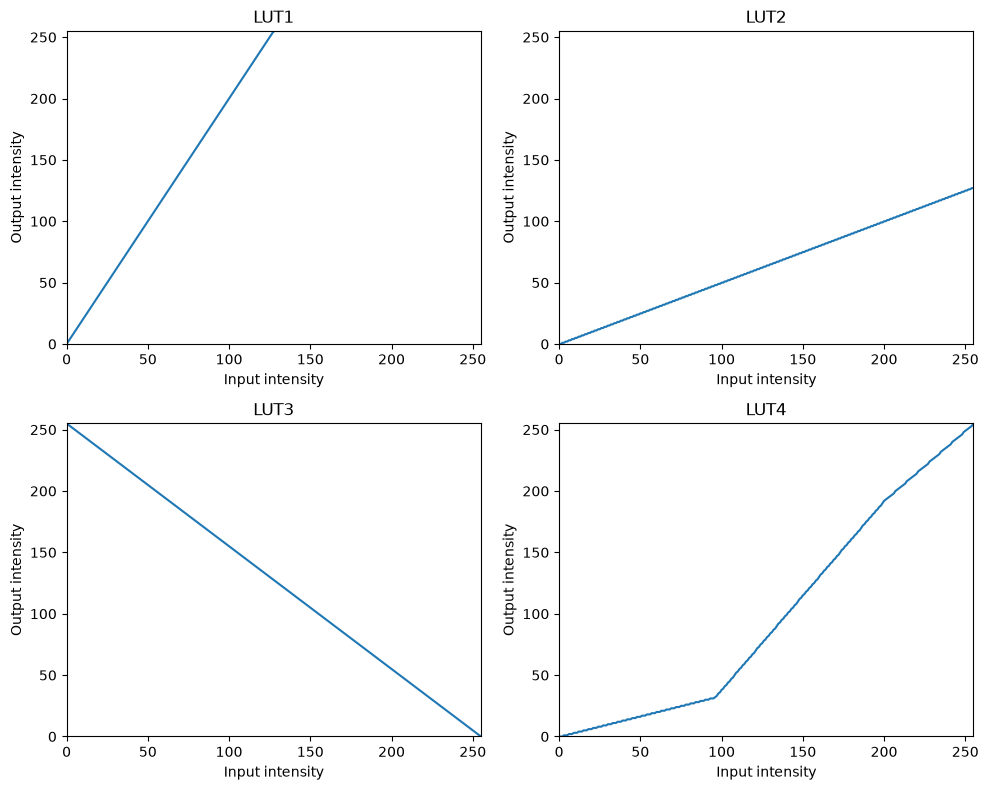

In [4]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.plot(x, LUT1)
plt.title('LUT1')
plt.xlabel('Input intensity')
plt.ylabel('Output intensity')
plt.xlim(0, 255)
plt.ylim(0, 255)

plt.subplot(2, 2, 2)
plt.plot(x, LUT2)
plt.title('LUT2')
plt.xlabel('Input intensity')
plt.ylabel('Output intensity')
plt.xlim(0, 255)
plt.ylim(0, 255)

plt.subplot(2, 2, 3)
plt.plot(x, LUT3)
plt.title('LUT3')
plt.xlabel('Input intensity')
plt.ylabel('Output intensity')
plt.xlim(0, 255)
plt.ylim(0, 255)

plt.subplot(2, 2, 4)
plt.plot(x, LUT4)
plt.title('LUT4')
plt.xlabel('Input intensity')
plt.ylabel('Output intensity')
plt.xlim(0, 255)
plt.ylim(0, 255)

plt.tight_layout()
plt.show()

## 3) 1)에서 생성한 LUT을 이용해서 영상을 변환하시오. 

### (a) function Image_Adjust_LUT(a,b)를 만드시오. 
Input parameters: a: input image, b: LUT 
Output: returns adjusted image 

In [5]:
def Image_Adjust_LUT(a, b):
    return b[a]

### (b) 영상 ‘x-ray.png’를 읽으시오. 

In [6]:
# (b) Read x-ray.png
x_ray = plt.imread('x-ray.png')

# PNG가 [0, 1] float 형식으로 읽힌 경우 [0, 255] uint8로 변환
if x_ray.dtype != np.uint8:
    x_ray = np.uint8(x_ray * 255)

print(x_ray.shape)
print(x_ray.dtype)
print(x_ray.min(), x_ray.max())

(214, 300)
uint8
0 255


### (c) function Image_Adjust_LUT를 이용해서 읽어들인 x-ray LUT1, 2, 3, 4를 이용하여 변환하시
오

In [7]:
x_ray_LUT1 = Image_Adjust_LUT(x_ray, LUT1)
x_ray_LUT2 = Image_Adjust_LUT(x_ray, LUT2)
x_ray_LUT3 = Image_Adjust_LUT(x_ray, LUT3)
x_ray_LUT4 = Image_Adjust_LUT(x_ray, LUT4)

### (d) (c) 에서 변환한 4개의 이미지를 하나의 figure에 출력하시오. (subplot(), imshow()) 

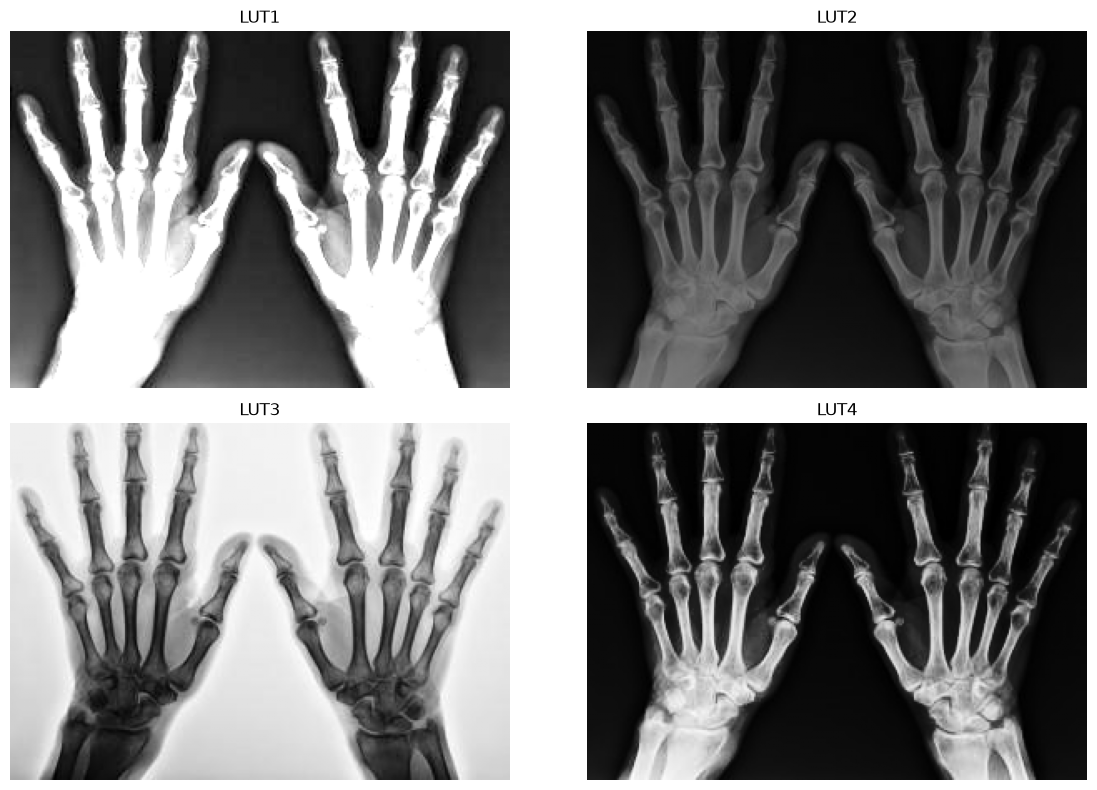

In [8]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(x_ray_LUT1, cmap='gray', vmin=0, vmax=255)
plt.title('LUT1')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(x_ray_LUT2, cmap='gray', vmin=0, vmax=255)
plt.title('LUT2')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(x_ray_LUT3, cmap='gray', vmin=0, vmax=255)
plt.title('LUT3')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(x_ray_LUT4, cmap='gray', vmin=0, vmax=255)
plt.title('LUT4')
plt.axis('off')

plt.tight_layout()
plt.show()

# 2. Histogram Equalization 

## 2-1. Histogram Equalization

## 1) 1.(c) 의 LUT2의 결과 이미지에 대해 histogram equalization 을 수행하시오. 

In [9]:
# Histogram Equalization
x_ray_LUT2_HE = ex.equalize_hist(x_ray_LUT2)

# [0, 1] float → [0, 255] uint8
x_ray_LUT2_HE = np.uint8(x_ray_LUT2_HE * 255)

# 확인
print(x_ray_LUT2.dtype, x_ray_LUT2.min(), x_ray_LUT2.max())
print(x_ray_LUT2_HE.dtype, x_ray_LUT2_HE.min(), x_ray_LUT2_HE.max())

uint8 0 127
uint8 0 255


## 2) 1)의 두 영상을 출력하시오. 이때 uint8 형식의 0-255 scale 로 영상과 histograms 를
출력하시오. 두 영상과 histograms 를 비교하여 차이점을 4 장에서 배운 이론을 근간으로
간단히 설명하시오. 

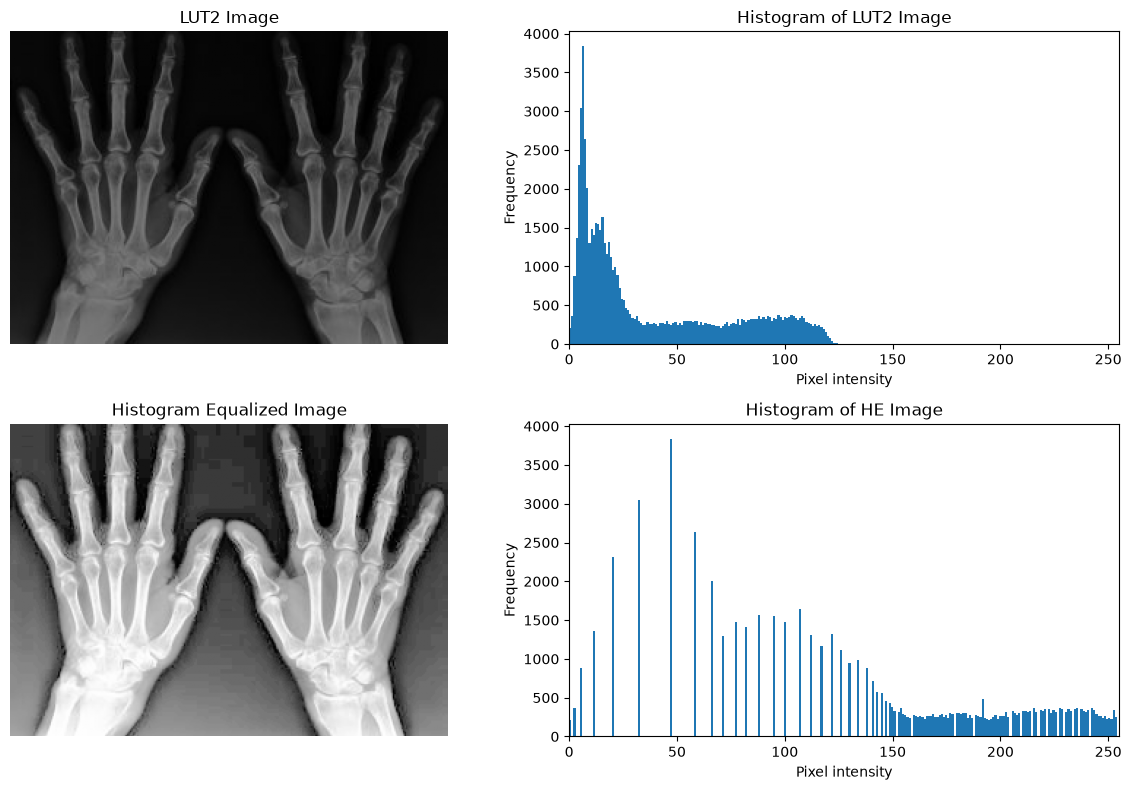

In [10]:
plt.figure(figsize=(12, 8))

# LUT2 image
plt.subplot(2, 2, 1)
plt.imshow(x_ray_LUT2, cmap='gray', vmin=0, vmax=255)
plt.title('LUT2 Image')
plt.axis('off')

# Histogram of LUT2
plt.subplot(2, 2, 2)
plt.hist(x_ray_LUT2.ravel(), bins=256, range=[0, 255])
plt.title('Histogram of LUT2 Image')
plt.xlabel('Pixel intensity')
plt.ylabel('Frequency')
plt.xlim([0, 255])

# Histogram Equalized image
plt.subplot(2, 2, 3)
plt.imshow(x_ray_LUT2_HE, cmap='gray', vmin=0, vmax=255)
plt.title('Histogram Equalized Image')
plt.axis('off')

# Histogram after HE
plt.subplot(2, 2, 4)
plt.hist(x_ray_LUT2_HE.ravel(), bins=256, range=[0, 255])
plt.title('Histogram of HE Image')
plt.xlabel('Pixel intensity')
plt.ylabel('Frequency')
plt.xlim([0, 255])

plt.tight_layout()
plt.show()

LUT2는 원본 픽셀의 밝기 값을 절반으로 감소시키므로 히스토그램이 0~127 범위에 집중되고 영상이 전체적으로 어둡게 나타난다. Histogram Equalization을 수행하면 누적분포함수(CDF)를 이용하여 픽셀의 밝기 값이 0~255의 더 넓은 범위에 재분배된다. 이에 따라 영상의 대비(contrast)가 향상되어 해부학적 구조를 더욱 뚜렷하게 구분할 수 있다. 또한 영상의 밝기 값은 이산적이므로 Histogram Equalization을 수행한 후의 히스토그램이 완벽하게 균일한 분포를 이루지는 않는다.

# 3. Histogram Specification (아래의 순서로 하거나, 결과가 나오도록 자유롭게 코딩해도 무방함) 

## 1) Read the ‘x_ray2.png’ and store it into ‘x_ray2’ matrix. 

In [11]:
x_ray2 = plt.imread('x_ray2.png')

if x_ray2.dtype != np.uint8:
    x_ray2 = np.uint8(x_ray2 * 255)

print(x_ray2.shape)
print(x_ray2.dtype)
print(x_ray2.min(), x_ray2.max())

(214, 300)
uint8
0 255


## 2) Do Histogram Equalization of ‘x_ray2’ and save the result into ‘x_ray_HE’ variable. 

In [12]:
x_ray_HE = ex.equalize_hist(x_ray2)

# [0, 1] float -> [0, 255] uint8
x_ray_HE = np.uint8(x_ray_HE * 255)

print(x_ray_HE.dtype)
print(x_ray_HE.min(), x_ray_HE.max())

uint8
0 255


## 3) Display the variable ‘x_ray2’ and ‘x_ray_HE’ within the same figure window. 

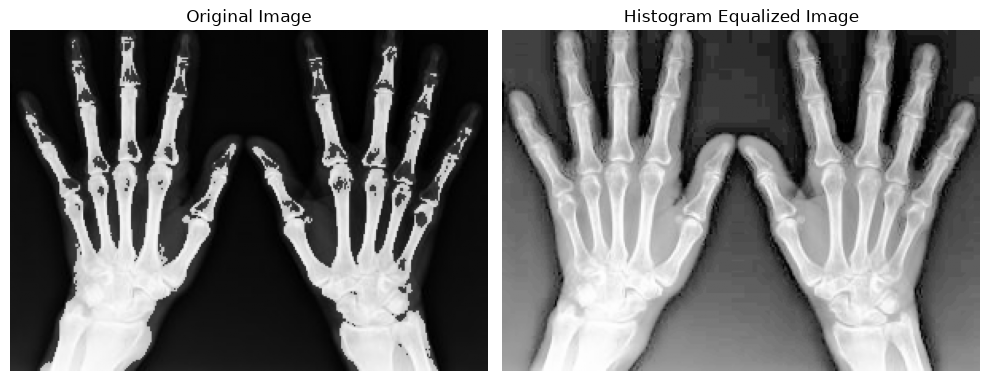

In [13]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(x_ray2, cmap='gray', vmin=0, vmax=255)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(x_ray_HE, cmap='gray', vmin=0, vmax=255)
plt.title('Histogram Equalized Image')
plt.axis('off')

plt.tight_layout()
plt.show()

## 4) Make your own histogram ‘hist_desired’ (i.e. ()) (1x256 형태의 row vector 형태로 생성.) 

### Desired Histogram

### Desired Histogram

입력 영상의 histogram을 참고하여 piecewise-linear 형태의 desired histogram을 설계하였다. 
낮은 밝기 영역의 과도한 집중을 줄이고, 중·고 밝기 영역을 보다 넓게 분포시켜 
배경과 뼈 구조 사이의 대비를 유지하면서 밝은 영역의 세부 구조가 과도하게 포화되는 것을 줄이고자 하였다.

(256,)


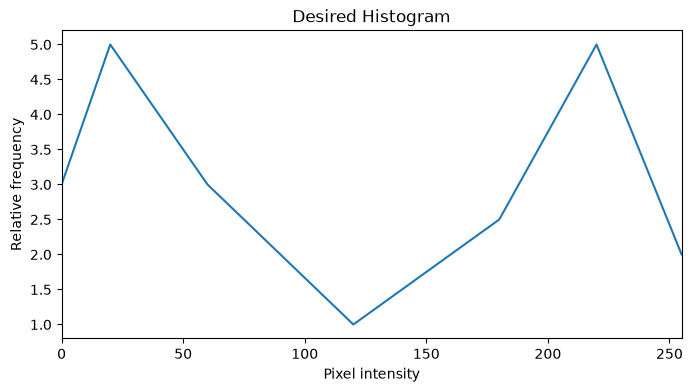

In [14]:
# Make desired histogram

u = np.arange(256)

# Control points
x_points = np.array([0, 20, 60, 120, 180, 220, 255])
y_points = np.array([3, 5, 3, 1, 2.5, 5, 2])

# Piecewise-linear desired histogram
hist_desired = np.interp(u, x_points, y_points)

print(hist_desired.shape)

plt.figure(figsize=(8, 4))
plt.plot(u, hist_desired)
plt.title('Desired Histogram')
plt.xlabel('Pixel intensity')
plt.ylabel('Relative frequency')
plt.xlim([0, 255])
plt.show()

## 5) Make histogram of ‘x_ray2’ and store it into ‘hist_xray2’ (i.e. ()). 

In [15]:
hist_xray2, bins = np.histogram(x_ray2, bins=256, range=[0, 255])

print(hist_xray2.shape)

(256,)


## 6) Make CDF of ‘hist_desired’ and ‘hist_xray2’ and store them into ‘cdf_desired’ (i.e. ()) and 
‘cdf_input’ (i.e. ()) respectively. 

In [16]:
# 6) CDF

cdf_desired = np.cumsum(hist_desired)
cdf_desired = cdf_desired / cdf_desired[-1]

cdf_input = np.cumsum(hist_xray2)
cdf_input = cdf_input / cdf_input[-1]

## 7) Generate the Look Up Table to convert input pixel values ‘r’ (x_ray2) to output value ‘u’ (cdf_desired) 
by () and 
( ) and store it into ‘LUT’. Draw a plot of  versus .

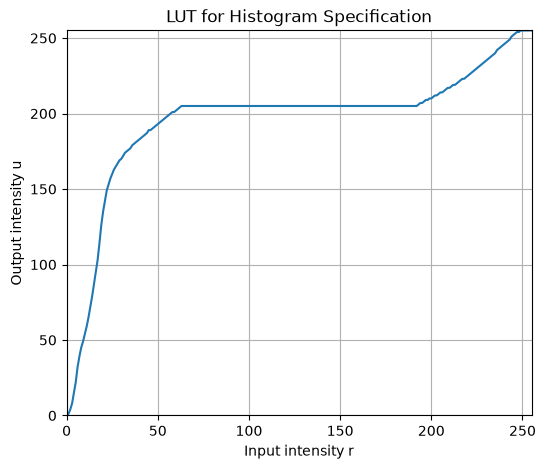

In [17]:
LUT = np.zeros(256, dtype=np.uint8)

for r in range(256):
    u_out = np.argmin(np.abs(cdf_desired - cdf_input[r]))
    LUT[r] = u_out

plt.figure(figsize=(6, 5))
plt.plot(np.arange(256), LUT)
plt.title('LUT for Histogram Specification')
plt.xlabel('Input intensity r')
plt.ylabel('Output intensity u')
plt.xlim([0, 255])
plt.ylim([0, 255])
plt.grid()
plt.show()

## 8) Apply the LUT on the ‘x_ray2’ and store it into the ‘x_ray_HS’. (Make sure that data type of LUT 
should be uint8). 

In [18]:
x_ray_HS = LUT[x_ray2]
print("LUT dtype:", LUT.dtype)



LUT dtype: uint8


## 9) Display ‘x_ray_HE’ and ‘x_ray_HS’ within the same window.

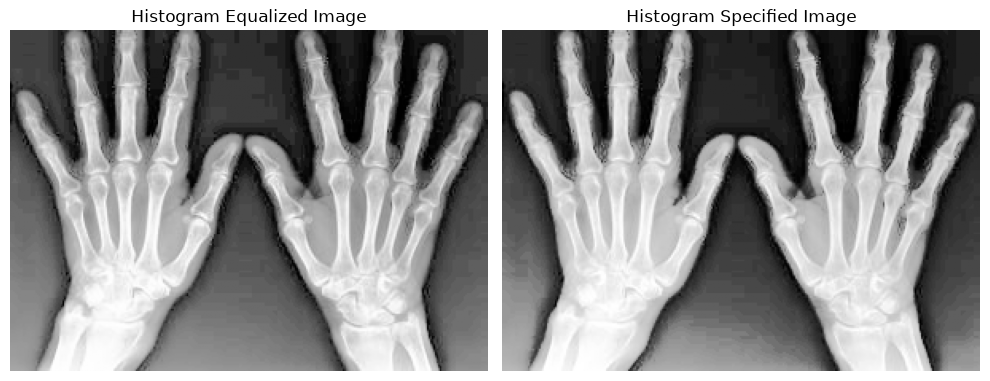

In [19]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(x_ray_HE, cmap='gray', vmin=0, vmax=255)
plt.title('Histogram Equalized Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(x_ray_HS, cmap='gray', vmin=0, vmax=255)
plt.title('Histogram Specified Image')
plt.axis('off')

plt.tight_layout()
plt.show()

Histogram Specification 결과가 더 적절하다고 판단하였다. Histogram Equalization 결과는 전체 gray level 범위를 넓게 사용하여 강한 contrast를 보였으나, 일부 밝은 영역이 과도하게 강조되는 경향이 나타났다.

Histogram Specification에서는 입력 영상의 histogram을 고려하여 piecewise-linear 형태의 desired histogram을 설계하였다. 낮은 밝기 영역의 과도한 집중을 줄이고 중·고 밝기 영역을 보다 넓게 분포시키도록 하였다.

입력 영상의 CDF와 desired histogram의 CDF를 대응시켜 생성한 LUT는 각 입력 intensity를 새로운 출력 intensity로 재매핑하였다. 그 결과 밝은 영역의 과도한 포화를 줄이면서도 뼈 구조와 주변 영역 사이의 contrast를 유지할 수 있었다.

따라서 본 실험에서는 Histogram Specification 결과가 Histogram Equalization 결과보다 전체적인 밝기 분포가 균형적이고 세부 구조가 보다 자연스럽게 표현되었다.